In [1]:
import torch
import os
import sys

os.environ["GEOMSTATS_BACKEND"] = "pytorch"
os.environ["SCIPY_ARRAY_API"] = "1"

import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA

from xp_datasets import get_plot_kde_grassmann, plot_projections

sys.path.append("../")
from lib_pca.lifted_pca import LiftedPCA
from lib_pca.uncertainty_aware_pca import UAPCA
from lib_pca.utils_kde import kde_stiefel
from lib_pca.utils_sqrtm import sqrtm

[KeOps] Warning : CUDA libraries not found or could not be loaded; Switching to CPU only.


In [2]:
def dataset_students_grades(n=100):
    """Reads student grades dataset file and creates corresponding distributions.

    Returns:
        list[MNDistribution]: List of distributions.
    """

    # Read data from file:
    # with open(Path(__file__).with_name("students_grades.csv")) as f:
    #     lines = f.readlines()

    lines = np.loadtxt("./data/students_grades.csv", delimiter=",", dtype=str)

    d = 4

    # Create distributions:
    samples = torch.zeros(len(lines), n, d)
    labels = []
    for i, vals in enumerate(lines):
        label = vals[0]
        mean = torch.tensor([float(v) for v in vals[1:5]])
        cov = torch.diag(torch.tensor([float(v) for v in vals[5:]]))

        samples[i] = mean + torch.randn(n, d) @ sqrtm(cov)
        labels.append(label)

    # Return distributions:
    return samples, labels

samples, name_labels = dataset_students_grades(100)

n_classes = samples.shape[0]
d = samples.shape[-1]

concat_samples = torch.cat([samples[k] for k in range(len(samples))], axis=0)
labels = torch.cat([torch.ones(100) * k for k in range(len(samples))], axis=0).type(torch.int64)

## PCA

In [3]:
## PCA

pca = PCA(n_components=2)
X_reduced = pca.fit_transform(concat_samples.numpy())

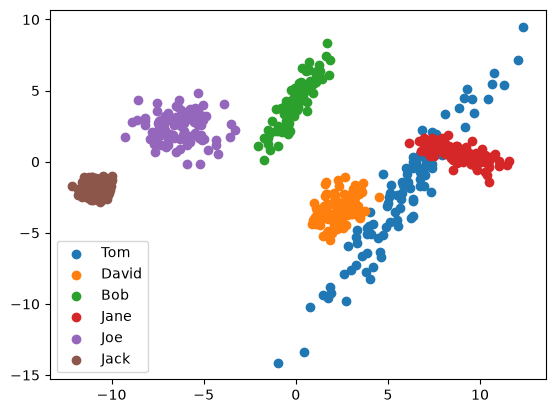

In [4]:
for k in range(6):
    plt.scatter(X_reduced[labels==k, 0], X_reduced[labels==k, 1], label=name_labels[k])

plt.legend()
plt.show()

## UAPCA

In [5]:
# Distributional PCA
pca_distributional = UAPCA(2)
pca_distributional.fit_from_samples(samples)
eigenvectors_distributional = pca_distributional.components_# .numpy()


pca_distributional_1component = UAPCA(1)
pca_distributional_1component.fit_from_samples(samples)
print("Barycenter cost:", pca_distributional.cost_barycenter(samples).item())

INFO:2026-10-12 21:52:03,003:jax._src.xla_bridge:812: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
INFO: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory


Barycenter cost: 11.873991926154357


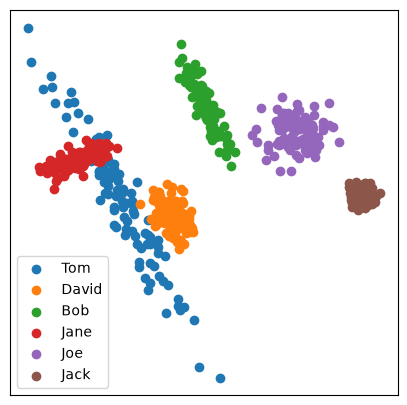

In [6]:
fig, ax = plt.subplots(
    nrows=1, 
    ncols=1,
    figsize=(5,5)
)

proj_points = torch.einsum("ij, ki -> kj", pca_distributional.components_, concat_samples).numpy()
for k in range(n_classes):
    ax.scatter(proj_points[labels == k, 0], proj_points[labels == k, 1], label=name_labels[k]) # , alpha=alpha[i*10+j])

ax.legend()

ax.set_xticks([])
ax.set_yticks([])

plt.show()

## Lifted PCA

In [7]:
lifted_pca = LiftedPCA(n_components=2, n_samples=100)
lifted_pca.fit(samples)
eigenvectors_lifted = lifted_pca.components_

print("Barycenter cost:", lifted_pca.cost_barycenter(samples).item())

Barycenter cost: 5.035685528888417


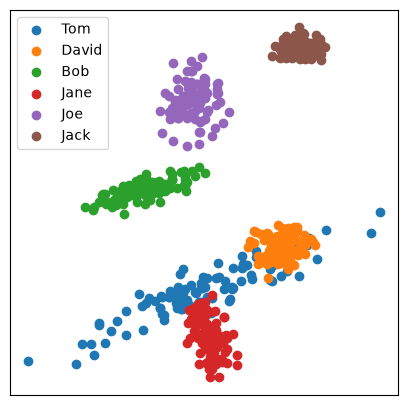

In [8]:
U_bary = lifted_pca.get_barycenter_components()

fig, ax = plt.subplots(
    nrows=1, 
    ncols=1,
    figsize=(5,5)
)

proj_points = torch.einsum("ij, ki -> kj", U_bary, concat_samples).numpy()
for k in range(n_classes):
    ax.scatter(proj_points[labels == k, 0], proj_points[labels == k, 1], label=name_labels[k]) # , alpha=alpha[i*10+j])

ax.legend()

ax.set_xticks([])
ax.set_yticks([])

plt.show()

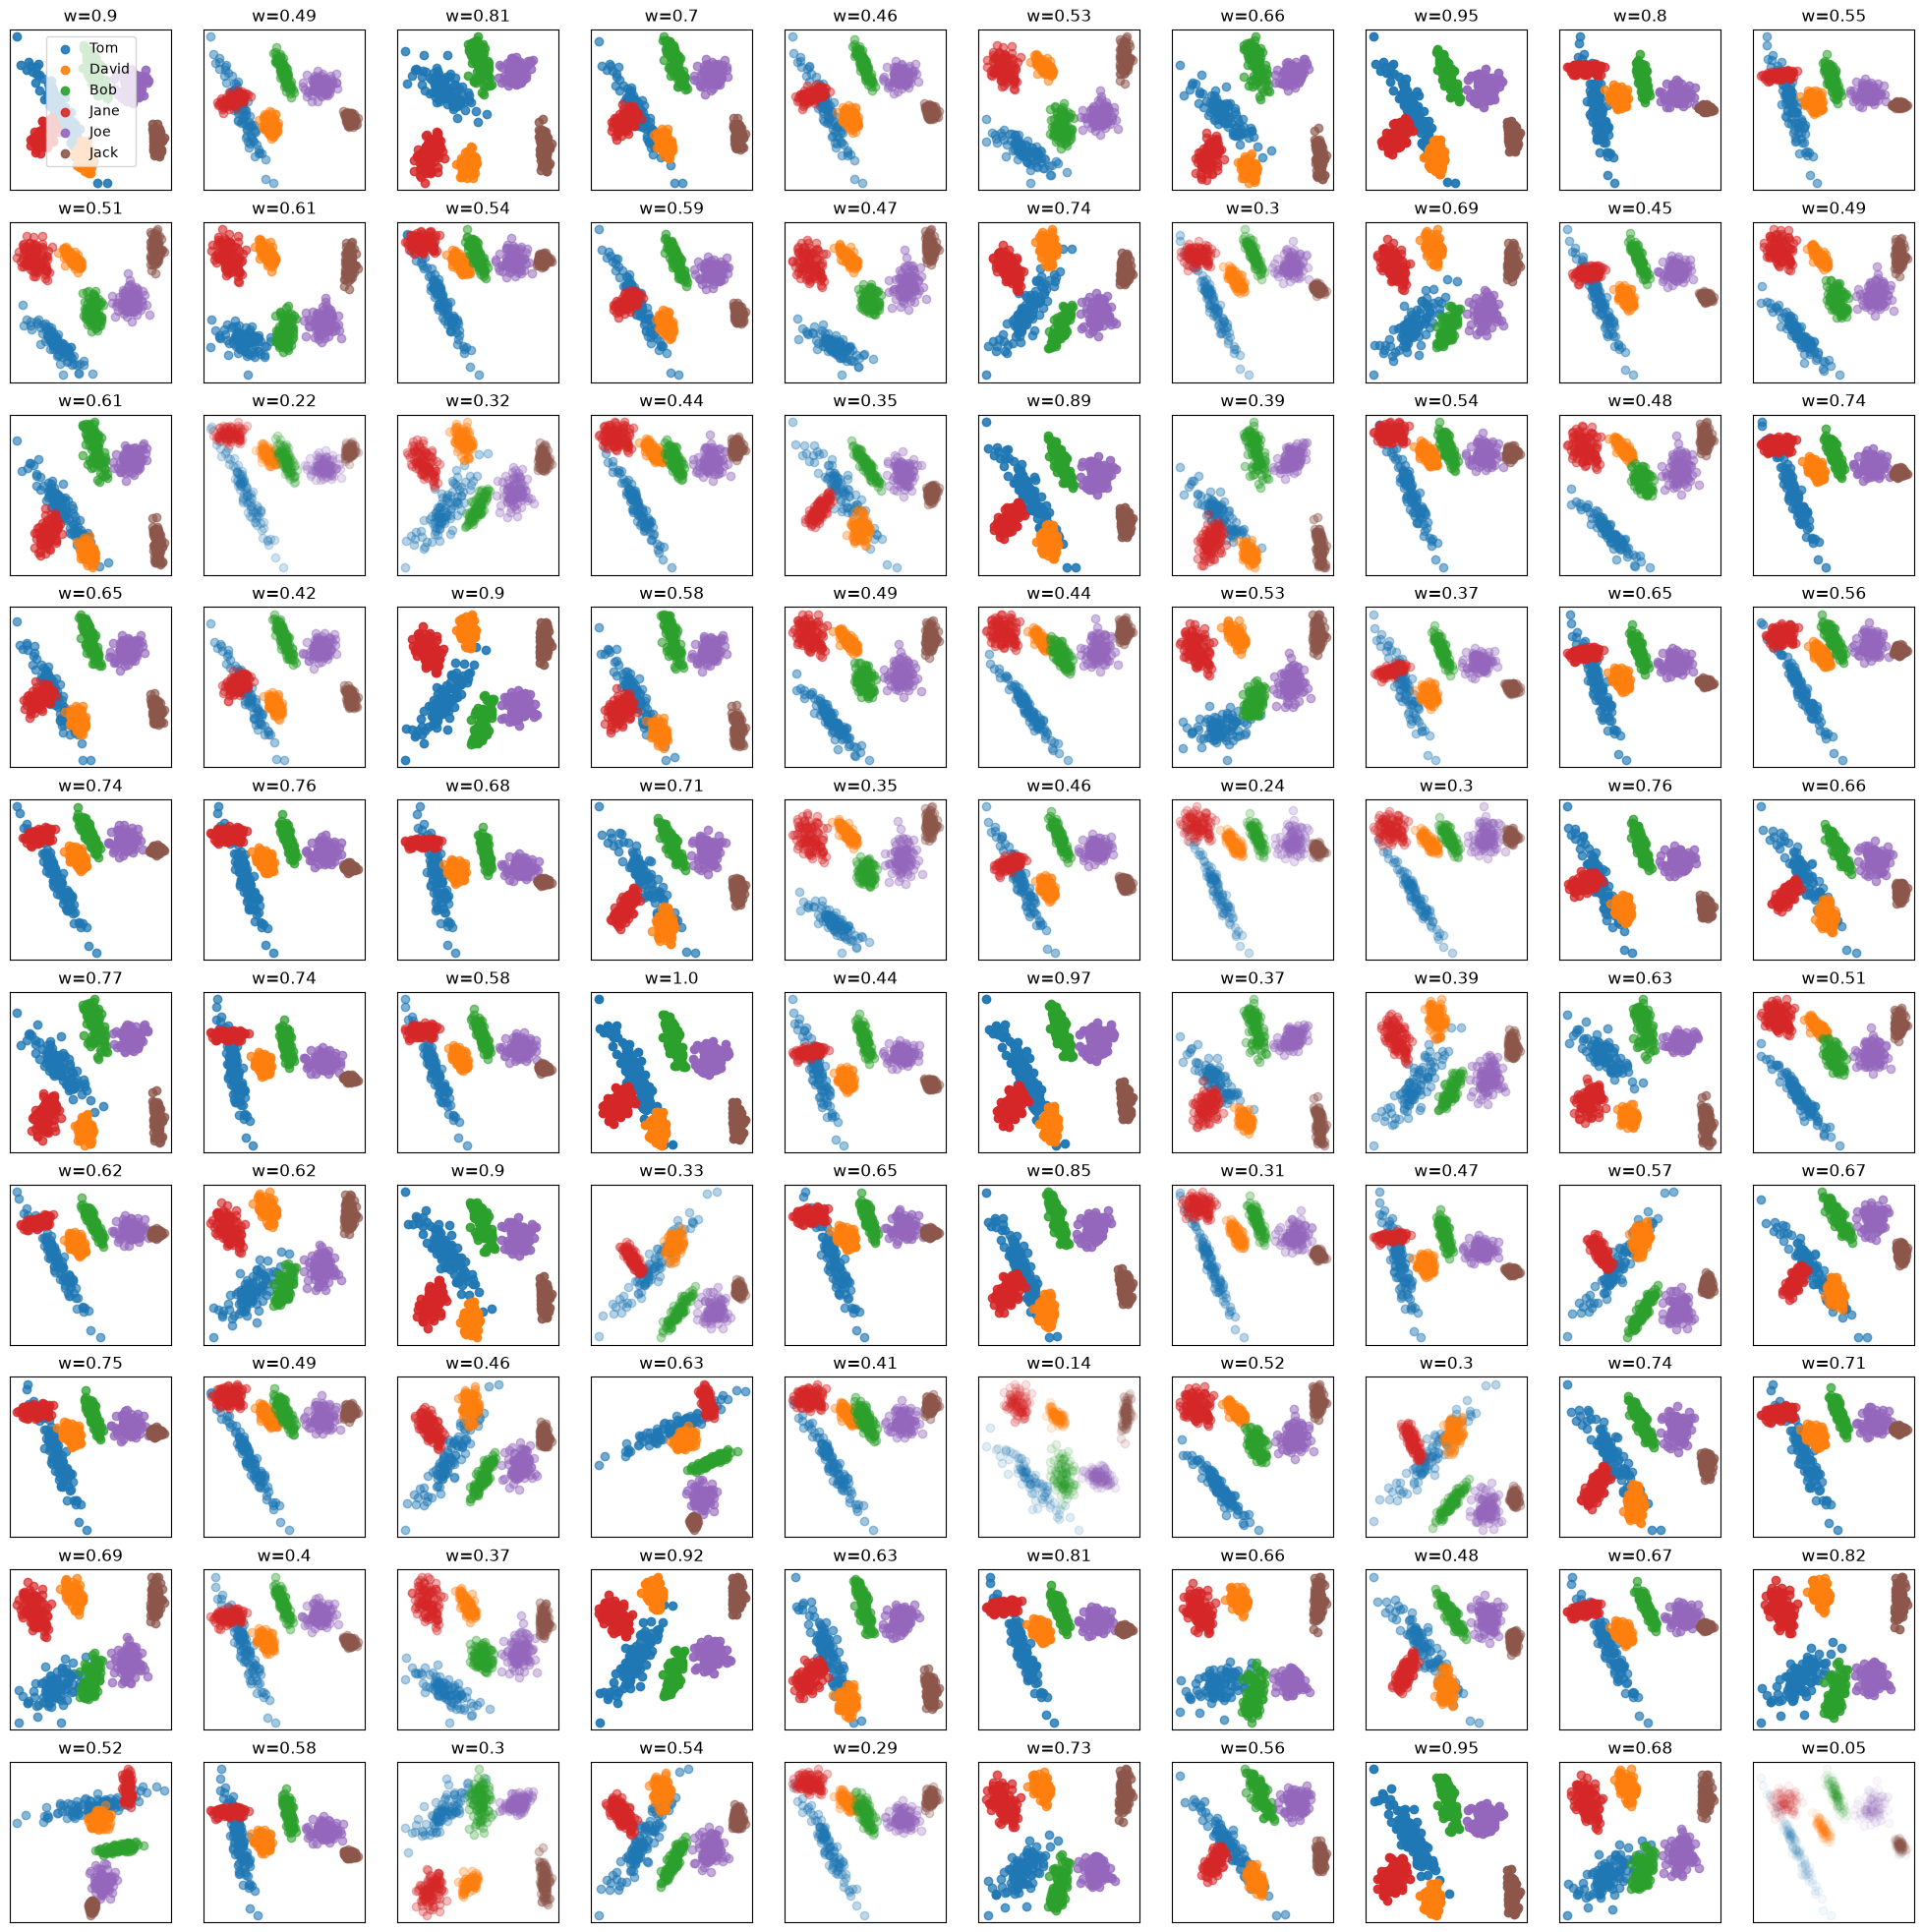

In [9]:
# weights = lifted_pca.weights_.numpy()
weights = kde_stiefel(lifted_pca.components_, lifted_pca.components_, 0.25).numpy()
min_weights = weights.min()
max_weights = weights.max()
diff = max_weights - min_weights
alpha = 0.05 + 0.95 * (weights - min_weights) / diff

fig, axes = plt.subplots(
    nrows=10, 
    ncols=10,
    figsize=(25,25)
)

for i in range(10):
    for j in range(10):
        U = lifted_pca.components_[i*10+j]
        proj_points = torch.einsum("ij, ki -> kj", U, concat_samples).numpy()
        for k in range(n_classes):
            axes[i, j].scatter(proj_points[labels == k, 0], proj_points[labels == k, 1], label=name_labels[k] , alpha=alpha[i*10+j])

        if i == 0 and j == 0:
            axes[i, j].legend()

        axes[i, j].set_xticks([])
        axes[i, j].set_yticks([])

        axes[i, j].set_title("w=" + str(round(alpha[i*10+j], 2)))

plt.show()

In [10]:
# ## KDE on PCA of projections

# centered_samples = lifted_pca.center_data(samples)

# L_projected_samples = []
# for k in range(len(centered_samples)):
#     projected_samples = lifted_pca.project_samples(centered_samples[k]).reshape(-1, 4)
#     L_projected_samples.append(projected_samples)

# full_projected_samples = torch.stack(L_projected_samples).reshape(-1, 4)

# pca = PCA(2)
# projected_samples_2D = pca.fit_transform(full_projected_samples)


# palette = ["blue", "orange", "green"]

# legend_handles = []

# for k in range(len(centered_samples)):
#     plot_gaussian_kde(projected_samples_2D[k*5000: (k+1)*5000], color=palette[k])

#     legend_handles.append(Line2D([0], [0], color=palette[k], lw=1.2, label=name_labels[k]))


# plt.legend(handles=legend_handles)


# plt.show()

In [11]:
# get_plot_kde_grassmann(lifted_pca, pca=pca_distributional, uapca=pca_distributional, title="KDE on Grassmannian of PCA subspaces")

In [12]:
# proj_low, proj_top, _, _, _ = get_plot_kde_grassmann(lifted_pca, pca=pca_distributional, uapca=pca_distributional, title="KDE on Grassmannian of PCA subspaces", get_outliers=True)

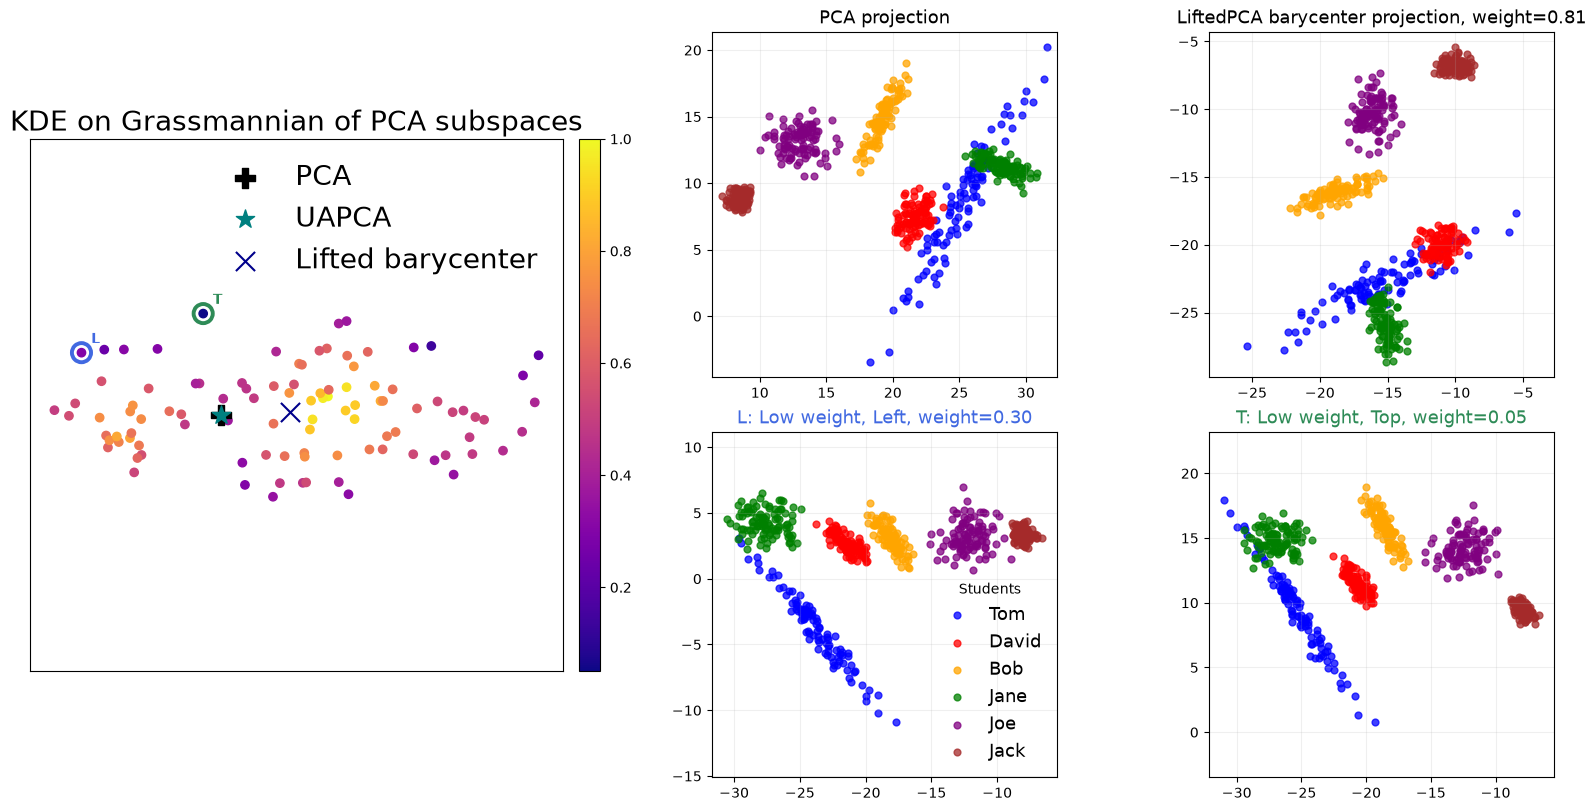

In [19]:
fig = plt.figure(figsize=(16, 8), constrained_layout=True)

outer_grid = fig.add_gridspec(1, 2, width_ratios=[1.35, 2.5])

projection_grid = outer_grid[1].subgridspec(2, 2)

ax_weights = fig.add_subplot(outer_grid[0])
ax_pca = fig.add_subplot(projection_grid[0, 0])
ax_barycenter = fig.add_subplot(projection_grid[0, 1])
ax_left_low = fig.add_subplot(projection_grid[1, 0])
ax_top_low = fig.add_subplot(projection_grid[1, 1])

proj_low, proj_top, alpha_low, alpha_top, alpha_bary = get_plot_kde_grassmann(
    lifted_pca, pca=pca_distributional, uapca=pca_distributional, title="KDE on Grassmannian of PCA subspaces", get_outliers=True, ax=ax_weights, fontsize=20
)

X_torch = concat_samples

class_colors = ["blue", "red", "orange", "green", "purple", "brown"]

plot_projections(X_torch, torch.from_numpy(pca.components_.T), labels, name_labels, ax=ax_pca, title="PCA projection", colors=class_colors)
plot_projections(X_torch, lifted_pca.get_barycenter_components(), labels, name_labels, ax=ax_barycenter,
                 title=f"LiftedPCA barycenter projection, weight={alpha_bary:.2f}", colors=class_colors)

plot_projections(X_torch, proj_low, labels, name_labels, ax=ax_left_low,
                 title=f"L: Low weight, Left, weight={alpha_low:.2f}", title_color="royalblue", colors=class_colors)

plot_projections(X_torch, proj_top, labels, name_labels, ax=ax_top_low,
                 title=f"T: Low weight, Top, weight={alpha_top:.2f}", title_color="seagreen", colors=class_colors)

ax_left_low.legend(title="Students", frameon=False, fontsize=13, ncols=1, loc="lower right")

plt.savefig("./Figures/Results_students.pdf", format="pdf", bbox_inches="tight")
plt.show()